In [1]:
from google.colab import files
files.upload()

Saving kaggle (1).json to kaggle (1).json


{'kaggle (1).json': b'{"username":"chauayush","key":"f0e72f3ade58b81742f66937f4b49578"}'}

In [2]:
import os
os.listdir()

['.config', 'kaggle (1).json', 'sample_data']

In [3]:
import os, shutil

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.move('kaggle (1).json', '/root/.kaggle/kaggle.json')
!chmod 600 /root/.kaggle/kaggle.json

In [4]:
!kaggle datasets download -d karakaggle/kaggle-cat-vs-dog-dataset
!unzip -q kaggle-cat-vs-dog-dataset.zip

Dataset URL: https://www.kaggle.com/datasets/karakaggle/kaggle-cat-vs-dog-dataset
License(s): unknown
100% 787M/787M [00:05<00:00, 148MB/s]



In [5]:
import os
from PIL import Image

path = '/content/kagglecatsanddogs_3367a/PetImages'

for folder in ['Cat', 'Dog']:
    folder_path = os.path.join(path, folder)

    for file in os.listdir(folder_path):
        file_path = os.path.join(folder_path, file)

        try:
            img = Image.open(file_path)
            img.verify()  # check corruption
        except:
            os.remove(file_path)

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


In [6]:
import tensorflow  as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten


In [7]:
train_ds = keras.utils.image_dataset_from_directory(
    directory='/content/kagglecatsanddogs_3367a/PetImages',
    validation_split=0.2,
    subset='training',
    labels='inferred',
    label_mode='int',
    seed=123,
    image_size=(256, 256),
    batch_size=32
)

val_ds = keras.utils.image_dataset_from_directory(
    directory='/content/kagglecatsanddogs_3367a/PetImages',
    validation_split=0.2,
    labels='inferred',
    subset='validation',
    seed=123,
    label_mode='int',
    image_size=(256, 256),
    batch_size=32
)

Found 24959 files belonging to 2 classes.
Using 19968 files for training.
Found 24959 files belonging to 2 classes.
Using 4991 files for validation.


In [8]:
import tensorflow as tf

train_ds = train_ds.apply(tf.data.experimental.ignore_errors())
val_ds = val_ds.apply(tf.data.experimental.ignore_errors())

Instructions for updating:
Use `tf.data.Dataset.ignore_errors` instead.


In [9]:
def process(image,label):
  image=tf.cast(image/255,tf.float32)
  return image,label
train_ds = train_ds.map(process)
val_ds = val_ds.map(process)


In [10]:
model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(54,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 54)             │         6,966 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            55 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,845,997 (56.63 MB)

 Trainable params: 14,845,997 (56.63 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [13]:
history=model.fit(train_ds,epochs=10,validation_data=val_ds)

Epoch 1/10
    618/Unknown 53s 68ms/step - accuracy: 0.6091 - loss: 0.6496

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


618/618 ━━━━━━━━━━━━━━━━━━━━ 65s 88ms/step - accuracy: 0.6693 - loss: 0.5980 - val_accuracy: 0.7157 - val_loss: 0.5481
Epoch 2/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 68s 79ms/step - accuracy: 0.7785 - loss: 0.4649 - val_accuracy: 0.7806 - val_loss: 0.4614
Epoch 3/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 51s 83ms/step - accuracy: 0.8337 - loss: 0.3690 - val_accuracy: 0.7950 - val_loss: 0.4641
Epoch 4/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 52s 84ms/step - accuracy: 0.8875 - loss: 0.2602 - val_accuracy: 0.7968 - val_loss: 0.5728
Epoch 5/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 52s 84ms/step - accuracy: 0.9419 - loss: 0.1474 - val_accuracy: 0.7694 - val_loss: 0.7653
Epoch 6/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 51s 83ms/step - accuracy: 0.9670 - loss: 0.0910 - val_accuracy: 0.7776 - val_loss: 1.0974
Epoch 7/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 52s 84ms/step - accuracy: 0.9769 - loss: 0.0671 - val_accuracy: 0.7858 - val_loss: 1.1757
Epoch 8/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 54s 87ms/step - accuracy: 0.9850 - loss: 0.0444 - val_accurac

In [14]:
#from keras.layers import BatchNormalization,Dropout

In [15]:
#model = Sequential()

#model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
#model.add(BatchNormalization())
#model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))
#
#model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
#model.add(BatchNormalization())
#model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))
#
#model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
#model.add(BatchNormalization())
#model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))
#
#model.add(Flatten())
#
#model.add(Dense(128,activation='relu'))
#model.add(Dropout(0.1))
#model.add(Dense(54,activation='relu'))
#model.add(Dropout(0.1))
#model.add(Dense(1,activation='sigmoid'))

In [16]:
#model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [17]:
#history=model.fit(train_ds,epochs=5,validation_data=val_ds)

In [18]:
import cv2

In [21]:
test_image = cv2.imread('/content/dog.jpg')

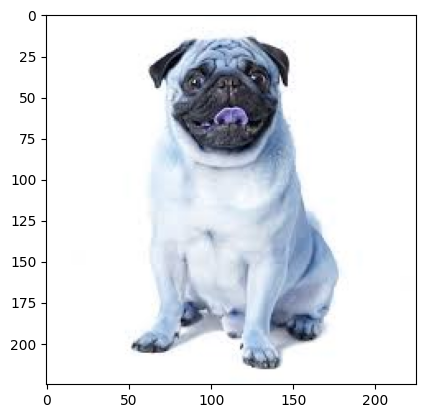

In [22]:
import matplotlib.pyplot as plt
plt.imshow(test_image)


In [23]:
test_image.shape

(225, 225, 3)

In [24]:
test_image = cv2.resize(test_image,(256,256))

In [25]:
test_input = test_image.reshape((1,256,256,3))

In [26]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 939ms/step


array([[1.]], dtype=float32)

In [27]:
test = cv2.imread('/content/cat.jpg')

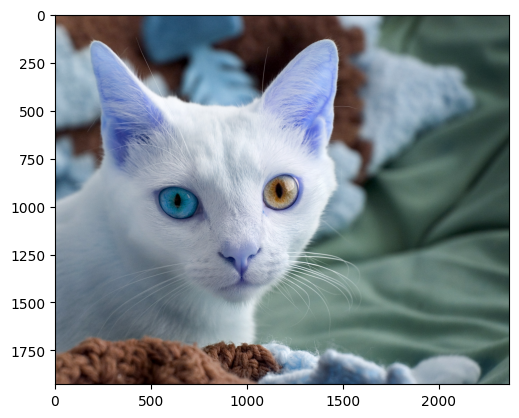

In [28]:
plt.imshow(test)

In [29]:
test.shape

(1927, 2370, 3)

In [30]:
test = cv2.resize(test,(256,256))


In [31]:
input = test.reshape((1,256,256,3))

In [32]:
model.predict(input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


array([[0.]], dtype=float32)